# 8장 실습. 평가 하네스와 결정 로깅

이 책은 엔진을 여러 번 바꾼다. Jev, Laya 기본 체크포인트, 파인튜닝한 Laya, 로컬 LLM 의 확률을 읽는 AnyJev, 로컬 LLM 그 자체다. 엔진마다 다른 데이터로 재면 숫자끼리 비교가 되지 않는다. 그래서 이 노트북에서 평가셋 파일 하나와 그것을 재는 방법을 정한다. 뒤의 장들은 평가셋 파일(`data/eval_v1.jsonl`)을 읽고, 채점·지표 함수는 이 노트북의 것을 그대로 옮겨 쓴다.

| 과제 | 원본 | 질문 유형 | 무엇을 묻나 |
|---|---|---|---|
| topic | KLUE YNAT (CC BY-SA 4.0) | choice 7지선다 | 뉴스 제목의 분야 |
| entails | KLUE NLI (CC BY-SA 4.0) | noul | 전제가 참이면 가설도 반드시 참인가 |
| positive | NSMC (CC0 1.0) | noul | 영화 리뷰가 긍정적인가 |
| similarity | KLUE STS (CC BY-SA 4.0) | score 6단계 | 두 문장의 의미가 얼마나 같은가 |

하네스가 제대로 재는지는 언어 모델 없이도 확인해야 한다. 그래서 과제마다 학습한 TF-IDF + 로지스틱 회귀 분류기를 기준선 엔진으로 함께 만든다.

0장(`nb00_setup.ipynb`)에서 원본 데이터를 받아 두어야 한다. 8.9절은 Jev 에 800건을 보낸다(약 0.02달러).

In [1]:
import os, json, csv, random, hashlib, time
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, requests
import koreanize_matplotlib  # noqa: F401
from dotenv import load_dotenv
from requests.adapters import HTTPAdapter, Retry

load_dotenv()
DATA, RAW, RESULTS, OUT = Path("data"), Path("data/raw"), Path("results/eval_v1"), Path("out")
assert RAW.exists(), "원본 데이터가 없다. nb00_setup 을 먼저 실행한다"
RESULTS.mkdir(parents=True, exist_ok=True); OUT.mkdir(exist_ok=True)
TASKS = ["topic", "entails", "positive", "similarity"]
COLOR = {"topic": "#2a78d6", "entails": "#eb6834", "positive": "#1baf7a", "similarity": "#eda100"}
pd.set_option("display.precision", 3)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

read_jsonl = lambda p: [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()]
write_jsonl = lambda p, rows: Path(p).write_text("".join(json.dumps(r, ensure_ascii=False, default=str) + "\n" for r in rows), encoding="utf-8")

## 8.1 공통 평가셋 구축

평가셋은 각 데이터의 **검증(dev) 분할**에서만 뽑고, 학습(train) 분할은 4부의 파인튜닝용으로 남긴다. 과제마다 200개를 정답 분포 비율대로 뽑고 시드를 고정한다. 누가 만들어도 같은 파일이 나와야 하므로 SHA-256 으로 확인한다. 2판에서 만든 파일과 같다면 해시가 `1b565ae5…` 로 시작한다.

먼저 질문이다. 평가셋과 4부의 학습 데이터가 같은 질문을 쓴다.

In [2]:
choice = lambda instructions, criteria: {"type": "choice", "instructions": instructions, "criteria": criteria}
score = lambda instructions, levels: {"type": "score", "instructions": instructions, "criteria": levels}
noul = lambda instructions, true, false: {"type": "noul", "instructions": instructions, "criteria": {"true": true, "false": false}}

TOPICS = {"IT과학": "IT, 인터넷, 과학기술, 연구 성과에 관한 기사", "경제": "기업, 금융, 부동산, 산업, 경기에 관한 기사",
          "사회": "사건사고, 교육, 노동, 환경, 지역 소식에 관한 기사", "생활문화": "건강, 여행, 공연, 책, 날씨, 생활 정보에 관한 기사",
          "세계": "다른 나라의 정치·경제·사회 소식에 관한 기사", "스포츠": "경기 결과, 선수, 구단, 대회에 관한 기사",
          "정치": "국회, 정당, 정부, 선거, 남북관계에 관한 기사"}
SIM_LEVELS = ["두 문장의 의미가 완전히 다르다", "주제만 비슷하고 내용은 다르다", "일부 내용만 겹친다",
              "핵심 내용은 같지만 중요한 차이가 있다", "대부분 같고 사소한 차이만 있다", "두 문장의 의미가 완전히 같다"]
QUESTIONS = {
    "topic": {"topic": choice("이 뉴스 제목이 속한 분야", TOPICS)},
    "entails": {"entails": noul("`premise` 가 사실이라면 `hypothesis` 도 반드시 사실이다",
                                "premise 만 읽고도 hypothesis 가 참이라고 확정할 수 있다",
                                "hypothesis 가 premise 와 모순되거나, premise 만으로는 참인지 알 수 없다")},
    "positive": {"positive": noul("리뷰 작성자는 이 영화를 긍정적으로 평가한다",
                                  "칭찬하거나 추천하거나 만족을 드러낸다", "비판하거나 실망하거나 추천하지 않는다")},
    "similarity": {"similarity": score("`sentence1` 과 `sentence2` 의 의미가 얼마나 같은가", SIM_LEVELS)},
}

원본 한 행을 평가 항목 하나로 바꾸는 함수다. KLUE 는 주석자들의 표를 남겼으므로 그 비율(`gold_dist`)도 함께 담는다. 4부에서 교사 분포로 쓴다.

In [3]:
load_json = lambda name: json.loads((RAW / name).read_text(encoding="utf-8"))

def load_nsmc(name):
    rows = list(csv.DictReader((RAW / name).open(encoding="utf-8"), delimiter="\t", quoting=csv.QUOTE_NONE))
    return [r for r in rows if r["document"] and r["document"].strip()]

def item_topic(r):
    votes = Counter(r["annotations"]["annotations"]["first-scope"])
    return {"id": r["guid"], "task": "topic", "state": r["title"], "gold": r["label"],
            "gold_dist": {k: votes.get(k, 0) / sum(votes.values()) for k in TOPICS}}

def item_entails(r):
    votes = [r[k] for k in ("author", "label2", "label3", "label4", "label5")]
    return {"id": r["guid"], "task": "entails", "state": {"premise": r["premise"], "hypothesis": r["hypothesis"]},
            "gold": r["gold_label"] == "entailment", "gold_dist": {"true": votes.count("entailment") / len(votes)},
            "nli_label": r["gold_label"]}

def item_positive(r):
    return {"id": f"nsmc_{r['id']}", "task": "positive", "state": r["document"].strip(), "gold": r["label"] == "1", "gold_dist": None}

def item_similarity(r):
    ann = r["annotations"]["annotations"]
    c = Counter(int(round(a)) for a in ann)
    return {"id": r["guid"], "task": "similarity", "state": {"sentence1": r["sentence1"], "sentence2": r["sentence2"]},
            "gold": int(round(r["labels"]["label"])), "gold_value": r["labels"]["label"],
            "gold_dist": {str(k): c.get(k, 0) / len(ann) for k in range(6)}}

# 과제 → (dev 파일, train 파일, 읽기, 항목 만들기, 층화 기준)
SOURCES = {"topic": ("ynat-v1.1_dev.json", "ynat-v1.1_train.json", load_json, item_topic, "gold"),
           "entails": ("klue-nli-v1.1_dev.json", "klue-nli-v1.1_train.json", load_json, item_entails, "nli_label"),
           "positive": ("ratings_test.txt", "ratings_train.txt", load_nsmc, item_positive, "gold"),
           "similarity": ("klue-sts-v1.1_dev.json", "klue-sts-v1.1_train.json", load_json, item_similarity, "gold")}

정답 비율을 지키며 뽑는다. 과제의 정답 갈래마다 몫을 비율대로 나누고, 소수점 아래로 버려진 몫은 많이 버려진 갈래부터 하나씩 더 준다(최대 잉여 배분).

In [4]:
def stratified(items, key, n, rng):
    groups = defaultdict(list)
    for it in items:
        groups[it[key]].append(it)
    quota = {g: n * len(v) / len(items) for g, v in groups.items()}
    take = {g: int(q) for g, q in quota.items()}
    for g in sorted(quota, key=lambda g: quota[g] - take[g], reverse=True)[: n - sum(take.values())]:
        take[g] += 1
    out = [it for g in sorted(groups, key=str) for it in rng.sample(groups[g], take[g])]
    rng.shuffle(out)
    return out

rng = random.Random(2026)
sets = {t: stratified([make(r) for r in read(dev)], key, 200, rng) for t, (dev, _, read, make, key) in SOURCES.items()}
write_jsonl(DATA / "eval_v1.jsonl", [it | {"questions": QUESTIONS[t]} for t, its in sets.items() for it in its])
card = {"version": "v1", "seed": 2026, "n_per_task": 200, "sha256": hashlib.sha256((DATA / "eval_v1.jsonl").read_bytes()).hexdigest(),
        "counts": {t: dict(Counter(str(i["gold"]) for i in v)) for t, v in sets.items()}}
(DATA / "eval_v1.card.json").write_text(json.dumps(card, ensure_ascii=False, indent=2), encoding="utf-8")
print("sha256", card["sha256"][:16], "| 2판과 같은가:", card["sha256"].startswith("1b565ae5"))
pd.DataFrame(card["counts"]).fillna("").T

sha256 1b565ae5d24e96d7 | 2판과 같은가: True


,경제,정치,스포츠,생활문화,사회,세계,IT과학,False,True,4,3,0,2,5,1
topic,30.0,16.0,13.0,30.0,81.0,18.0,12.0,,,,,,,,
entails,,,,,,,,134.0,66.0,,,,,,
positive,,,,,,,,99.0,101.0,,,,,,
similarity,,,,,,,,,,47.0,37.0,25.0,38.0,17.0,36.0


topic 은 「사회」가 81개로 가장 많다. 원본 분포를 그대로 따랐기 때문이다. entails 는 함의·중립·모순 세 갈래를 고르게 뽑은 뒤 「함의인가」로 바꿨으므로 참이 3분의 1 이다. 늘 가장 많은 답을 고르는 엔진도 topic 에서 40%, entails 에서 67% 를 맞힌다. 정확도는 이 다수결 비율과 견줘 읽는다.

In [5]:
items = read_jsonl(DATA / "eval_v1.jsonl")
by = {t: [i for i in items if i["task"] == t] for t in TASKS}
pd.DataFrame([{"과제": t, "질문 유형": by[t][0]["questions"][t]["type"], "정답": by[t][0]["gold"],
               "state": json.dumps(by[t][0]["state"], ensure_ascii=False)[:70]} for t in TASKS])

,과제,질문 유형,정답,state
0,topic,choice,경제,"""신한은행 비대면 근저당권 해지 프로세스 도입"""
1,entails,noul,False,"{""premise"": ""최종 우승팀을 겨루는 데모데이는 글로벌 스타트업 축제인 컴업..."
2,positive,noul,False,"""이거 재밌다는글 말투만봐도 알바인거 티난다ㅡㅡ한국영화의 퇴보 스킵해서 10분안으로..."
3,similarity,score,4,"{""sentence1"": ""샤워실도 깔끔하고 하수물도 잘 빠집니다."", ""sente..."


## 8.2 라벨 불확실성과 주석자 불일치

평가셋은 다수결 정답 하나로 채점하지만 사람끼리도 갈린 항목이 적지 않다. 그런 항목에서 엔진이 0.5 남짓의 확률을 내는 것은 실패가 아니라 정직한 답이다.

In [6]:
p_ent = Counter(round(i["gold_dist"]["true"], 1) for i in by["entails"])
pd.Series({"topic: 세 사람이 같은 분야를 고른 제목": np.mean([max(i["gold_dist"].values()) == 1 for i in by["topic"]]),
           "entails: 다섯 사람의 표가 갈린 항목": sum(v for k, v in p_ent.items() if 0 < k < 1) / 200,
           "similarity: 가장 많은 표를 받은 단계의 평균 득표율": np.mean([max(i["gold_dist"].values()) for i in by["similarity"]])},
          name="값").to_frame()

,값
topic: 세 사람이 같은 분야를 고른 제목,0.620
entails: 다섯 사람의 표가 갈린 항목,0.110
similarity: 가장 많은 표를 받은 단계의 평균 득표율,0.598


## 8.3 기준선 엔진: TF-IDF·로지스틱 회귀

과제마다 학습 분할에서 최대 4만 개를 뽑아 글자 1~3그램 TF-IDF 와 로지스틱 회귀를 학습한다. entails 는 전제·가설의 특징과 둘의 곱을 붙이고, similarity 는 두 문장의 코사인 유사도·단어 자카드·길이 비로 6단계를 분류한다. 언어 모델은 쓰지 않는다.

In [7]:
import re
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

words = lambda s: set(re.findall(r"\w+", s))

def sts_features(v, states):
    a, b_ = v.transform([s["sentence1"] for s in states]), v.transform([s["sentence2"] for s in states])
    cos = np.asarray(a.multiply(b_).sum(axis=1)).ravel()
    jac = np.array([len(words(s["sentence1"]) & words(s["sentence2"])) / max(1, len(words(s["sentence1"]) | words(s["sentence2"]))) for s in states])
    lr = np.array([min(len(s["sentence1"]), len(s["sentence2"])) / max(len(s["sentence1"]), len(s["sentence2"])) for s in states])
    return np.column_stack([cos, jac, lr, cos ** 2, jac ** 2, cos * jac])

# 과제 → (TF-IDF 를 학습할 글, 특징, 정규화 C)
SPEC = {"topic": (lambda S: S, lambda v, S: v.transform(S), 4.0),
        "positive": (lambda S: S, lambda v, S: v.transform(S), 4.0),
        "entails": (lambda S: [s[f] for f in ("premise", "hypothesis") for s in S],
                    lambda v, S: hstack([v.transform([s["premise"] for s in S]), v.transform([s["hypothesis"] for s in S]),
                                         v.transform([s["premise"] for s in S]).multiply(v.transform([s["hypothesis"] for s in S]))]).tocsr(), 1.0),
        "similarity": (lambda S: [s[f] for f in ("sentence1", "sentence2") for s in S], sts_features, 1.0)}

def fit(task, max_train=40_000):
    _, train, read, make, _ = SOURCES[task]
    rows = [make(r) for r in read(train)]
    rows = random.Random(0).sample(rows, min(max_train, len(rows)))      # 4만 개보다 작은 과제는 전부 쓴다
    texts, feats, C = SPEC[task]
    S = [r["state"] for r in rows]
    v = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 3), min_df=2, max_features=200_000, sublinear_tf=True).fit(texts(S))
    return v, LogisticRegression(max_iter=4000, C=C).fit(feats(v, S), [r["gold"] for r in rows])

t0 = time.perf_counter()
tfidf = {t: fit(t) for t in TASKS}
print(f"학습 {time.perf_counter() - t0:.0f}초 (CPU)")

학습 52초 (CPU)


기준선 엔진도 Jev 와 같은 모양으로 답하게 한다. 그러면 채점 코드가 엔진을 가리지 않는다.

In [8]:
def tfidf_post(item):
    (task, q), = item["questions"].items()
    v, clf = tfidf[task]
    t0 = time.perf_counter()
    p = dict(zip(map(str, clf.classes_), clf.predict_proba(SPEC[task][1](v, [item["state"]]))[0]))
    answer = {"noul": lambda: {"noul": p["True"]},
              "choice": lambda: {"choice": max(p, key=p.get), "probabilities": p},
              "score": lambda: {"score": sum(int(k) * x for k, x in p.items()), "probabilities": p}}[q["type"]]()
    return {"model": "tfidf-baseline-1", "answers": {task: answer}, "usage": {"input_tokens": 0}, "_latency_s": time.perf_counter() - t0}

## 8.4 평가 하네스와 보정 지표

`run()` 은 항목마다 엔진을 부르고 `judge()` 로 채점해 기록 한 줄을 만든다. 엔진 자리에는 항목을 받아 Jev 모양의 응답을 돌려주는 함수면 무엇이든 들어간다.

- 확신(conf): 고른 답의 확률. noul 은 `max(p, 1−p)`
- 정답: choice 는 고른 답, noul 은 `p ≥ 0.5`, score 는 확률이 가장 큰 단계를 정답과 견준다
- ECE: 같은 폭 15구간마다 평균 확신과 정답률의 차이를 항목 수로 가중 평균
- Brier: `(확신 − 정답 여부)²` 의 평균
- 처리율@5%: 확신 높은 순으로 받아들일 때 받아들인 것의 오류율이 5% 이하로 유지되는 최대 비율

In [9]:
def probs_of(answer):
    return answer.get("probabilities") or {"true": answer["noul"], "false": 1 - answer["noul"]}

def judge(item, resp):
    (task, q), = item["questions"].items()
    pr = {str(k): float(v) for k, v in probs_of(resp["answers"][task]).items()}
    best = max(pr, key=pr.get)
    pred = {"noul": lambda: pr["true"] >= 0.5, "choice": lambda: best, "score": lambda: int(best)}[q["type"]]()
    return {"id": item["id"], "task": item["task"], "qtype": q["type"], "gold": item["gold"], "gold_value": item.get("gold_value"),
            "model": resp["model"], "pred": pred, "probs": pr, "conf": pr[best], "correct": bool(pred == item["gold"]),
            "input_tokens": resp["usage"]["input_tokens"], "latency_s": resp["_latency_s"]}

def run(items, engine, workers=1):
    with ThreadPoolExecutor(workers) as ex:
        return list(ex.map(lambda it: judge(it, engine(it)), items))

noul 의 `probs` 는 `{"true": p, "false": 1−p}` 로 펼친다. 그래서 확신이 자연스럽게 `max(p, 1−p)` 가 된다. 지표 함수다.

In [10]:
def ece(conf, ok, bins=15):
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return float(sum(abs(conf[idx == i].mean() - ok[idx == i].mean()) * (idx == i).sum() for i in np.unique(idx)) / len(conf))

def coverage_at_risk(conf, ok, risk=0.05):
    order = np.argsort(-conf, kind="stable")
    c, y, k = conf[order], ok[order], np.arange(1, len(conf) + 1)
    cut = np.append(c[1:] != c[:-1], True) & (np.cumsum(1 - y) / k <= risk)     # 같은 확신값 묶음 중간에서는 자르지 않는다
    return float(np.max(k[cut], initial=0) / len(conf))

arrays = lambda recs: (np.array([r["conf"] for r in recs]), np.array([r["correct"] for r in recs], float))

def summarize(recs):
    conf, ok = arrays(recs)
    return {"n": len(recs), "accuracy": ok.mean(), "mean_conf": conf.mean(), "ece": ece(conf, ok),
            "brier": float(np.mean((conf - ok) ** 2)), "coverage@5%": coverage_at_risk(conf, ok),
            "latency_p50_ms": 1000 * np.median([r["latency_s"] for r in recs]), "input_tokens": sum(r["input_tokens"] for r in recs)}

report = lambda recs: pd.DataFrame({t: summarize([r for r in recs if r["task"] == t]) for t in TASKS} | {"ALL": summarize(recs)}).T

In [11]:
records = run(items, tfidf_post)
rep = report(records)
rep["majority"] = [max(Counter(str(i["gold"]) for i in by[t]).values()) / 200 for t in TASKS] + [np.nan]
rep

,n,accuracy,mean_conf,ece,brier,coverage@5%,latency_p50_ms,input_tokens,majority
topic,200.0,0.815,0.710,0.122,0.160,0.300,0.509,0.0,0.405
entails,200.0,0.675,0.682,0.045,0.206,0.030,1.715,0.0,0.670
positive,200.0,0.820,0.816,0.037,0.126,0.480,0.486,0.0,0.505
similarity,200.0,0.305,0.513,0.239,0.294,0.005,0.954,0.0,0.235
ALL,800.0,0.654,0.680,0.048,0.196,0.185,0.882,0.0,NaN


표를 읽는 순서는 이렇다.

- **정확도를 `majority` 와 견준다.** 다수결보다 나은지부터 본다.
- **정확도와 평균 확신을 견준다.** 평균 확신이 더 높으면 과신, 낮으면 과소 확신이다.
- **ECE 는 과제별로 본다.** `ALL` 행의 ECE 는 네 과제를 섞어 잰 값이라 과제 사이의 과신과 과소 확신이 상쇄된다.
- **ECE 가 작다고 좋은 엔진은 아니다.** 확신을 늘 0.5~0.7 에 몰아 두면 아무것도 구별하지 못해도 ECE 가 작다. 처리율@5% 를 함께 본다.

similarity 는 6단계라 정확히 맞힌 비율보다 오차로 본다.

In [12]:
sim = [r for r in records if r["task"] == "similarity"]
score_errors = lambda recs: {"평균 절대 오차": np.mean([abs(sum(int(k) * v for k, v in r["probs"].items()) - r["gold_value"]) for r in recs]),
                             "한 단계 안": np.mean([abs(r["pred"] - r["gold"]) <= 1 for r in recs])}
pd.Series(score_errors(sim), name="TF-IDF").to_frame()

,TF-IDF
평균 절대 오차,1.139
한 단계 안,0.605


## 8.5 부트스트랩 신뢰구간

과제당 200개로 잰 숫자는 얼마나 믿을 수 있을까. 항목을 복원 추출해 2,000번 다시 재면 95% 구간이 나온다. 뒤 장에서 엔진 둘을 비교할 때, 차이가 이 구간 폭보다 작으면 우열을 말하지 않는다.

In [13]:
def bootstrap(recs, n_boot=2000, seed=0):
    conf, ok = arrays(recs)
    idx = np.random.default_rng(seed).integers(0, len(conf), (n_boot, len(conf)))
    accs, eces = ok[idx].mean(1), [ece(conf[i], ok[i]) for i in idx]
    return {"정확도 95%": f"{np.percentile(accs, 2.5):.3f}–{np.percentile(accs, 97.5):.3f}",
            "ECE 95%": f"{np.percentile(eces, 2.5):.3f}–{np.percentile(eces, 97.5):.3f}"}

pd.DataFrame({t: bootstrap([r for r in records if r["task"] == t]) for t in TASKS}).T

,정확도 95%,ECE 95%
topic,0.760–0.865,0.096–0.181
entails,0.610–0.735,0.039–0.123
positive,0.765–0.875,0.036–0.099
similarity,0.245–0.370,0.192–0.309


## 8.6 신뢰도 도표

확신을 구간으로 나누고, 구간마다 평균 확신(가로)과 실제 정답률(세로)을 찍는다. 대각선 위에 놓이면 보정이 잘된 것이다. 점의 크기는 구간에 든 항목 수다.

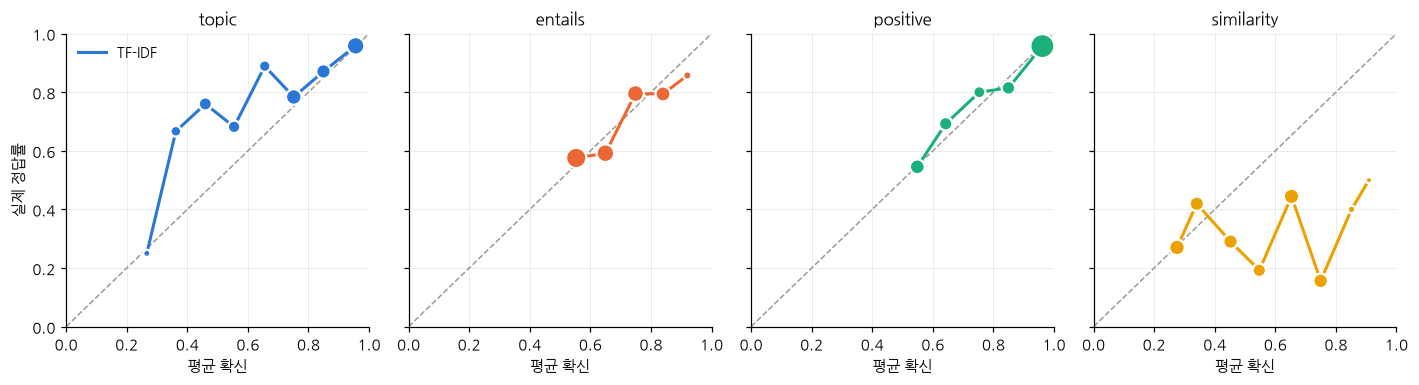

In [14]:
def reliability(recs, bins=10):
    conf, ok = arrays(recs)
    idx = np.clip(np.searchsorted(np.linspace(0, 1, bins + 1), conf, side="left") - 1, 0, bins - 1)
    return [(conf[idx == i].mean(), ok[idx == i].mean(), (idx == i).sum()) for i in np.unique(idx)]

def plot_reliability(engines, path):
    fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), dpi=110, sharey=True)
    for ax, t in zip(axes, TASKS):
        ax.plot([0, 1], [0, 1], ls="--", lw=1, color="#9a9a96")
        for name, (recs, color) in engines.items():
            x, y, n = zip(*reliability([r for r in recs if r["task"] == t]))
            ax.plot(x, y, lw=2, color=color or COLOR[t], label=name)
            ax.scatter(x, y, s=[12 + 2.5 * k for k in n], color=color or COLOR[t], edgecolor="white", linewidth=1.5, zorder=3)
        ax.set_title(t, fontsize=11); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("평균 확신"); ax.grid(alpha=0.25, lw=0.6)
    axes[0].set_ylabel("실제 정답률"); axes[0].legend(frameon=False, fontsize=9, loc="upper left")
    fig.tight_layout(); fig.savefig(OUT / path, bbox_inches="tight"); plt.show()

plot_reliability({"TF-IDF": (records, None)}, "nb08_reliability_tfidf.png")

## 8.7 처리율–오류율 곡선과 임계값 운영

보정을 재는 이유는 임계값을 정하기 위해서다. 임계값마다 몇 %를 자동 처리하고, 처리한 것 가운데 몇 %가 틀리는지 본다.

In [15]:
def threshold_table(recs, thresholds=(0.5, 0.6, 0.7, 0.8, 0.9, 0.95)):
    conf, ok = arrays(recs)
    return pd.DataFrame([{"임계": t, "처리율": (conf >= t).mean(), "처리분 오류율": pd.Series(1 - ok[conf >= t]).mean()} for t in thresholds])

pd.concat({t: threshold_table([r for r in records if r["task"] == t]).set_index("임계") for t in TASKS}, axis=1)

topic         entails         positive         similarity        
        처리율 처리분 오류율     처리율 처리분 오류율      처리율 처리분 오류율        처리율 처리분 오류율
임계                                                                     
0.50  0.780   0.147   1.000   0.325    1.000   0.180      0.505   0.713
0.60  0.670   0.119   0.670   0.276    0.835   0.126      0.375   0.680
0.70  0.580   0.121   0.425   0.200    0.705   0.092      0.195   0.795
0.80  0.395   0.076   0.205   0.195    0.605   0.074      0.035   0.571
0.90  0.240   0.042   0.035   0.143    0.470   0.043      0.010   0.500
0.95  0.135   0.000   0.000     NaN    0.285   0.018      0.000     NaN

같은 표를 곡선으로 그리면 엔진끼리 비교하기 쉽다. 가로가 처리율, 세로가 처리분 오류율이다. 아래에 있을수록 같은 처리율에서 덜 틀린다. 처리한 것이 없는 임계값의 오류율은 비어 있다(`NaN`).

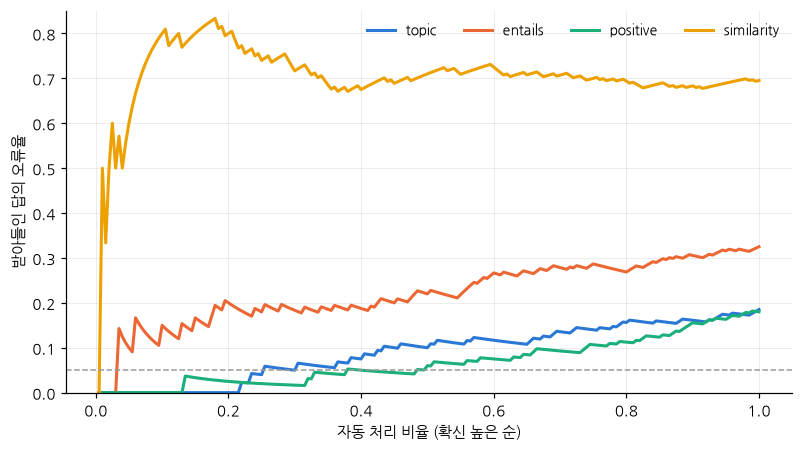

In [16]:
def risk_curve(recs):
    conf, ok = arrays(recs)
    order = np.argsort(-conf, kind="stable")
    k = np.arange(1, len(conf) + 1)
    return k / len(conf), np.cumsum(1 - ok[order]) / k

fig, ax = plt.subplots(figsize=(7.4, 4.2), dpi=110)
for t in TASKS:
    ax.plot(*risk_curve([r for r in records if r["task"] == t]), lw=2, color=COLOR[t], label=t)
ax.axhline(0.05, ls="--", lw=1, color="#9a9a96")
ax.set_xlabel("자동 처리 비율 (확신 높은 순)"); ax.set_ylabel("받아들인 답의 오류율"); ax.set_ylim(0, 0.85)
ax.legend(frameon=False, ncol=4, fontsize=9); ax.grid(alpha=0.25, lw=0.6)
fig.tight_layout(); fig.savefig(OUT / "nb08_coverage_risk.png", bbox_inches="tight"); plt.show()

## 8.8 결정 로그와 기록 저장

엔진 하나를 재면 기록 전체와 요약을 `results/eval_v1/` 에 남긴다. 기록 한 줄은 2장의 결정 로그와 같은 필드를 쓰고, 확률 분포 전체(`probs`)를 담는다. 분포가 있으면 임계값을 바꿨을 때 다시 묻지 않고 다시 계산한다. 평가셋 해시를 함께 적어, 같은 800문제로 잰 숫자인지 확인한다.

In [17]:
def save(name, recs, meta):
    write_jsonl(RESULTS / f"{name}.records.jsonl", recs)
    summary = {"engine": name, "eval_sha256": card["sha256"], **meta, "report": report(recs).to_dict("index")}
    (RESULTS / f"{name}.summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2, default=float), encoding="utf-8")

save("tfidf-baseline", records, {"engine_model": "tfidf-baseline-1", "note": "과제별 TF-IDF(char 1-3gram) + 로지스틱 회귀"})
print(json.dumps(records[0], ensure_ascii=False, indent=1))

{
 "id": "ynat-v1_dev_04100",
 "task": "topic",
 "qtype": "choice",
 "gold": "경제",
 "gold_value": null,
 "model": "tfidf-baseline-1",
 "pred": "경제",
 "probs": {
  "IT과학": 0.019578779232695243,
  "경제": 0.5185692280011687,
  "사회": 0.2021633267491692,
  "생활문화": 0.06505175681419617,
  "세계": 0.026999714517834117,
  "스포츠": 0.13757582256396444,
  "정치": 0.03006137212097206
 },
 "conf": 0.5185692280011687,
 "correct": true,
 "input_tokens": 0,
 "latency_s": 0.0010953119490295649
}


## 8.9 Jev 측정

같은 하네스에 Jev 를 꽂는다. 2장의 `ask()` 를 그대로 옮겨 온다. 800건을 `workers=4` 로 동시에 보낸다. Jev 의 한도(분당 1,200건) 안이다.

In [18]:
JEV_URL = os.getenv("JEV_URL", "https://api.typesafe.ai")
http = requests.Session()
retry = HTTPAdapter(max_retries=Retry(total=4, backoff_factor=0.5, status_forcelist=[408, 429, 500, 502, 503, 504]))
http.mount("https://", retry); http.mount("http://", retry)

def ask(state, questions, model="jev-latest"):
    r = http.post(f"{JEV_URL}/v1/systemone", timeout=60, headers={"Authorization": f"Bearer {os.environ['TYPESAFE_API_KEY']}"},
                  json={"model": model, "state": state, "questions": questions})
    r.raise_for_status()
    return r.json() | {"_latency_s": r.elapsed.total_seconds()}

t0 = time.perf_counter()
jev_rec = run(items, lambda it: ask(it["state"], it["questions"]), workers=4)
jrep = report(jev_rec)
save("jev", jev_rec, {"engine_model": ",".join(sorted({r["model"] for r in jev_rec}))})
print(f"{time.perf_counter() - t0:.0f}초 | 모델 {sorted({r['model'] for r in jev_rec})} | 입력 토큰 {jrep.loc['ALL', 'input_tokens']:,.0f}"
      f" → ${jrep.loc['ALL', 'input_tokens'] * 0.042 / 1e6:.3f}")
pd.concat({"TF-IDF": rep.drop(columns="majority"), "Jev": jrep}).swaplevel().sort_index().loc[TASKS + ["ALL"]]

37초 | 모델 ['jev-1.13.0'] | 입력 토큰 348,263 → $0.015


n  accuracy  mean_conf    ece  brier  coverage@5%  \
topic      Jev     200.0     0.800      0.897  0.102  0.138        0.565   
           TF-IDF  200.0     0.815      0.710  0.122  0.160        0.300   
entails    Jev     200.0     0.975      0.919  0.061  0.022        1.000   
           TF-IDF  200.0     0.675      0.682  0.045  0.206        0.030   
positive   Jev     200.0     0.850      0.831  0.036  0.101        0.665   
           TF-IDF  200.0     0.820      0.816  0.037  0.126        0.480   
similarity Jev     200.0     0.350      0.621  0.275  0.300        0.005   
           TF-IDF  200.0     0.305      0.513  0.239  0.294        0.005   
ALL        Jev     800.0     0.744      0.817  0.073  0.140        0.507   
           TF-IDF  800.0     0.654      0.680  0.048  0.196        0.185   

                   latency_p50_ms  input_tokens  
topic      Jev            178.909      101039.0  
           TF-IDF           0.509           0.0  
entails    Jev            174.133       83090.0  
           TF-IDF           1.715           0.0  
positive   Jev            170.163       72874.0  
           TF-IDF           0.486           0.0  
similarity Jev            177.325       91260.0  
           TF-IDF           0.954           0.0  
ALL        Jev            175.308      348263.0  
           TF-IDF           0.882           0.0

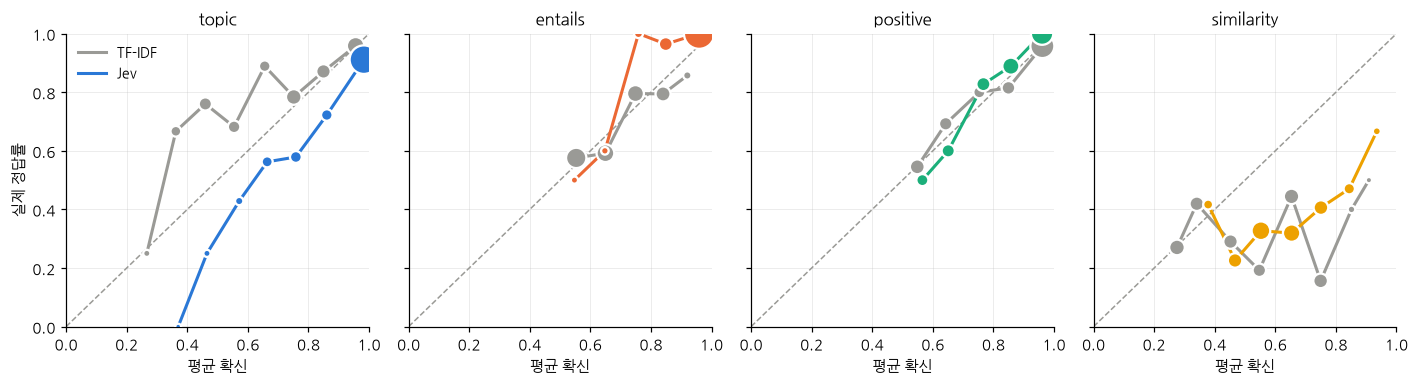

,평균 절대 오차,한 단계 안
TF-IDF,1.139,0.605
Jev,0.699,0.880


In [19]:
plot_reliability({"TF-IDF": (records, "#9a9a96"), "Jev": (jev_rec, None)}, "nb08_reliability_jev.png")
pd.DataFrame({"TF-IDF": score_errors(sim), "Jev": score_errors([r for r in jev_rec if r["task"] == "similarity"])}).T

## 8.10 짝지은 비교

두 엔진의 정확도 차이가 우연인지 본다. 같은 항목을 짝지어 함께 복원 추출하면 항목의 난이도에서 오는 흔들림이 차이에서 빠진다. 차이의 95% 구간이 0 을 걸치지 않아야 차이가 있다고 말한다. 3부부터 엔진을 비교할 때 이 함수를 그대로 옮겨 쓴다.

In [20]:
def paired(a, b, n_boot=2000, seed=0):
    ib = {r["id"]: r for r in b}
    ca, cb = np.array([r["correct"] for r in a], float), np.array([ib[r["id"]]["correct"] for r in a], float)
    idx = np.random.default_rng(seed).integers(0, len(ca), (n_boot, len(ca)))
    d = cb[idx].mean(1) - ca[idx].mean(1)
    return {"A": ca.mean(), "B": cb.mean(), "차이 (B − A)": cb.mean() - ca.mean(),
            "95% 구간": f"{np.percentile(d, 2.5):+.3f} ~ {np.percentile(d, 97.5):+.3f}", "답이 갈린 항목": int((ca != cb).sum())}

pd.DataFrame({t: paired([r for r in records if r["task"] == t], [r for r in jev_rec if r["task"] == t]) for t in TASKS}).T

,A,B,차이 (B − A),95% 구간,답이 갈린 항목
topic,0.815,0.8,-0.015,-0.085 ~ +0.055,51
entails,0.675,0.975,0.3,+0.235 ~ +0.370,66
positive,0.82,0.85,0.03,-0.020 ~ +0.080,26
similarity,0.305,0.35,0.045,-0.045 ~ +0.135,87


A 는 TF-IDF, B 는 Jev 다. 결과 해석은 8장 본문에서 한다.

## 정리

- 평가셋 v1 은 공개 한국어 데이터 넷의 dev 분할에서 과제당 200개씩 800개다. 시드와 SHA-256 으로 고정했다.
- 확신은 고른 답의 확률, ECE 는 15구간, 처리율@5% 는 오류율 5% 이하로 자동 처리할 수 있는 비율이다.
- 정확도는 다수결과, 평균 확신은 정확도와 견줘 읽는다. ECE 는 과제별로 잰다.
- 과제당 200개면 정확도 구간이 0.1 남짓 벌어진다. 엔진 비교는 짝지은 부트스트랩으로 한다.
- 기록은 확률 분포 전체를 담아 `results/eval_v1/` 에 남는다. 3부와 4부가 같은 자로 다시 비교한다.